<a href="https://colab.research.google.com/github/jspanchu/4961_hw/blob/main/hw5_q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms
import torch

torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using {device} device")
if device == 'cuda':
  torch.backends.cuda.matmul.allow_tf32 = True
  torch.backends.cudnn.allow_tf32 = True

Using cuda device


In [2]:
# The CIFAR-10 dataset consists of 60000 32x32 colour images in 10 classes,
# with 6000 images per class. There are 50000 training images and 10000 test images.
to_tensor_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)), # go from [0,255] to [-1,1]
])
cifar10_train_dsets = datasets.CIFAR10(root="/content/work/cifar10", download=True, transform=to_tensor_transform)
cifar10_val_dsets = datasets.CIFAR10(root="/content/work/cifar10", train=False, download=True, transform=to_tensor_transform)
len(cifar10_train_dsets), len(cifar10_val_dsets)

(50000, 10000)

In [3]:
cnn = torch.nn.Sequential(
    # 1
    torch.nn.Conv2d(in_channels=3, out_channels=64, kernel_size=(5,5),),
    torch.nn.ReLU(),
    # 2
    torch.nn.MaxPool2d(kernel_size=(2,2),),
    # 3
    torch.nn.LazyConv2d(out_channels=32, kernel_size=(3,3),),
    torch.nn.ReLU(),
    # 4
    torch.nn.MaxPool2d(kernel_size=(2,2),),
    # 5
    torch.nn.LazyConv2d(out_channels=32, kernel_size=(3,3),),
    torch.nn.ReLU(),
    # 6
    torch.nn.Flatten(),
    # 7
    torch.nn.LazyLinear(out_features=64),
    torch.nn.ReLU(),
    # 8
    torch.nn.LazyLinear(out_features=10),
).to(device)
cnn

Sequential(
  (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): LazyConv2d(0, 32, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): LazyConv2d(0, 32, kernel_size=(3, 3), stride=(1, 1))
  (7): ReLU()
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): LazyLinear(in_features=0, out_features=64, bias=True)
  (10): ReLU()
  (11): LazyLinear(in_features=0, out_features=10, bias=True)
)

In [4]:
dummy_input = torch.randn(1, 3, 32, 32, device=device)
# Run a forward pass to init lazy layers
_ = cnn(dummy_input)
for layer in cnn:
    if isinstance(layer, torch.nn.Linear):
        torch.nn.init.kaiming_normal_(layer.weight)
        torch.nn.init.zeros_(layer.bias)

def train_once(epoch, model, data_loader, optimizer, loss_fn):
  model.train()
  avg_loss = 0.0
  avg_acc = 0.0
  for X, y in data_loader:
    X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    logits = model(X)
    loss = loss_fn(logits, y)
    loss.backward()
    optimizer.step()
    avg_loss += loss.item()
    avg_acc += (logits.argmax(dim=1) == y).float().mean().item()
  avg_loss /= len(data_loader)
  avg_acc /= len(data_loader)
  return avg_loss, avg_acc


def eval_once(epoch, model, data_loader, loss_fn):
  model.eval()
  avg_loss = 0.0
  avg_acc = 0.0
  for X, y in data_loader:
    X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)
    with torch.no_grad():
      logits = model(X)
      loss = loss_fn(logits, y)
      avg_loss += loss.item()
      avg_acc += (logits.argmax(dim=1) == y).float().mean().item()
  avg_loss /= len(data_loader)
  avg_acc /= len(data_loader)
  return avg_loss, avg_acc


optimizer = torch.optim.Adam(params=cnn.parameters(), lr=0.001)
loader_opts = {'batch_size': 64, 'shuffle': True, 'num_workers': 8, 'pin_memory': True}
train_data_loader = torch.utils.data.DataLoader(
    dataset=cifar10_train_dsets,
    **loader_opts)
val_data_loader = torch.utils.data.DataLoader(
    dataset=cifar10_val_dsets,
    **loader_opts)
loss_fn = torch.nn.CrossEntropyLoss()
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
n_epochs = 10
for epoch in range(n_epochs):
  avg_train_loss, avg_train_acc = train_once(epoch, cnn, train_data_loader, optimizer, loss_fn)
  avg_val_loss, avg_val_acc = eval_once(epoch, cnn, val_data_loader, loss_fn)
  print(f'[epoch {epoch}/{n_epochs}], train_loss={avg_train_loss:.4f} val_loss={avg_val_loss:.4f}')
  train_losses.append(avg_train_loss)
  val_losses.append(avg_val_loss)
  train_accuracies.append(avg_train_acc)
  val_accuracies.append(avg_val_acc)

[epoch 0/10], train_loss=1.5006 val_loss=1.2984
[epoch 1/10], train_loss=1.1595 val_loss=1.0695
[epoch 2/10], train_loss=0.9980 val_loss=0.9720
[epoch 3/10], train_loss=0.9053 val_loss=0.9015
[epoch 4/10], train_loss=0.8428 val_loss=0.9125
[epoch 5/10], train_loss=0.7959 val_loss=0.9028
[epoch 6/10], train_loss=0.7576 val_loss=0.8674
[epoch 7/10], train_loss=0.7241 val_loss=0.8523
[epoch 8/10], train_loss=0.6972 val_loss=0.8715
[epoch 9/10], train_loss=0.6671 val_loss=0.8595


Text(0.5, 0.98, 'Loss and accuracy of CNN (lr=0.001, batch_size=64)')

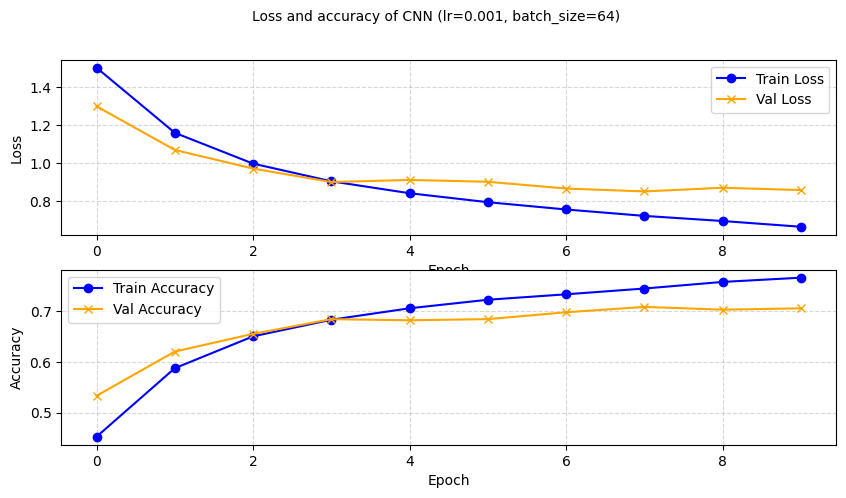

In [5]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(10, 5))
epochs = range(len(train_losses))
ax[0].plot(epochs, train_losses, label='Train Loss', color='blue', marker='o')
ax[0].plot(epochs, val_losses, label='Val Loss', color='orange', marker='x')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[1].plot(epochs, train_accuracies, label='Train Accuracy', color='blue', marker='o')
ax[1].plot(epochs, val_accuracies, label='Val Accuracy', color='orange', marker='x')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

title = f"Loss and accuracy of CNN (lr={optimizer.param_groups[0]['lr']}, batch_size=64)"
fig.suptitle(title, fontsize=10)